# 08B.6 — Final research evidence and competition package

**Goal.** Turn the whole project into one cohesive, defensible submission in which **every claim traces to an executed artifact**.

**Research narrative.** Raw tracking → Kinematics → Reliability → Stopwatch redundancy → FPCA → TCN fingerprint → NFL movement transfer → Context diagnosis → Football-outcome feasibility → Football transfer → Scouting decision intelligence.

**Evidence hierarchy — six levels, never collapsed into one success label.** measurement validated · descriptively repeatable · incremental information demonstrated · exploratory association · NFL predictive improvement established · unsupported or unresolved.

**How numbers reach the reports.** Each claim of `evidence_package.CLAIMS` names the persisted table it must be read from. This notebook reads those tables (it computes nothing new) and refreshes the `‹Cnn: …›` tokens of the three reports in place. A claim whose artifact does not exist stays `pending — run <notebook>`: it shows no number and is excluded from the executive narrative. Historical conclusions (Milestones 00–07) are read from their own tables and are not altered.

**This notebook runs in every branch** — football transfer frozen, exploratory or blocked.

**Prerequisites.** None is mandatory: whatever has been executed is reported; the rest is listed as pending.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full' — a smoke run never writes into the reports
SEED = 20261011
FORCE_REBUILD = False         # interface parity: everything is re-read on each run
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B6.1'
REGISTRY_VERSION = 'v1'
RENDER_REPORTS = True         # refresh the ‹Cnn: …› tokens of the three reports in place (full mode only)
REPORTS = ('NFL_BDB_2027_FOOTBALL_TRANSFER_RESEARCH.md', 'NFL_BDB_2027_SCOUTING_VALUE.md', 'NFL_BDB_2027_METHODS_AND_LIMITATIONS.md')

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import json

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import evidence_package as ep
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import outcome_semantics as osm
from nflbdb.research.advanced_movement import scouting_intelligence as si
from nflbdb.research.advanced_movement.artifacts import FootballStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = FootballStore(cfg, controls)
up = store.upstream
TABLES_ROOT, DATA_ROOT, FIGURES_ROOT = up.tables_dir, up.data_dir, up.figures_dir      # advanced-movement roots of THIS run mode
REPORT_DIR = cfg.paths.project_root / 'reports'
WRITE_REPORTS = RENDER_REPORTS and controls.save_tables and not controls.smoke
NB_ORDER = ['00_research_setup_and_data_audit', '01_sequence_eda_and_alignment', '02_functional_pca_baseline', '03_self_supervised_tcn',
            '04a_feature_characteristic_atlas', '04b_tcn_robustness_and_shortlist', '05a_nfl_movement_outcome_eda', '05b_nfl_outcome_reliability_and_freeze',
            '06a_transfer_cohort_and_leakage_audit', '06b_combine_to_nfl_transfer_benchmark', '06c_transfer_robustness_and_scouting_insights',
            '07a_nfl_outcome_context_decomposition', '07b_physics_aligned_transfer_hypotheses', '07c_detectability_and_information_ceiling',
            '07d_athletic_fingerprint_scorecard', '08a_football_outcome_feasibility', '08a2_outcome_semantics_and_opportunity_validation',
            '08b0_outcome_resolution_and_freeze', '08b1_football_outcome_reliability', '08b2_football_transfer_benchmark',
            '08b3_transfer_robustness_and_detectability', '08b4_incremental_movement_information', '08b5_scouting_decision_intelligence',
            '08b6_final_research_evidence_package']
try:
    REGISTRY = fr.load_registry(store, REGISTRY_VERSION)
except fr.FootballTransferBlocked as e:
    print('football registry not usable:', e)
    REGISTRY = None
BRANCH = fr.branch(REGISTRY)
PROV = {'notebook': '08b6_final_research_evidence_package.ipynb', 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed,
        'registry_hash': (REGISTRY or {}).get('version_hash'), 'branch': BRANCH['name']}
save = lambda df, c: store.write(df, c, '08B6', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check; reports are NOT written' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · football branch: **{BRANCH["label"]}** · tables `{cfg.paths.rel(TABLES_ROOT)}` · '
                 f'figures `{cfg.paths.rel(FIGURES_ROOT)}` · reports {"refreshed in place" if WRITE_REPORTS else "NOT written"}'))

**Run mode: `full`** (FULL) · football branch: **EXPLORATORY — source semantics inferred; definitions locked** · tables `reports/tables/advanced_movement` · figures `reports/figures/advanced_movement` · reports refreshed in place

In [3]:
validation = fv.run_all((fv.check_evidence_tokens_and_gate_f,))
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

check,status,detail
str,str,str
"""evidence_tokens_and_gate_f""","""PASS""","""claims without an executed artifact stay pending, outside the narrative, and fail Gate F"""


## 1 · Machine-readable evidence registry

One row per claim: the executive question it answers, the statement, the **value read from the artifact**, the sample size, the evidence level, the artifact path, whether it is executed, and its limitation.

The evidence level of a football-transfer claim is decided **by the artifact**, not by this notebook: *NFL predictive improvement established* only when 08B.2 reports a held-out improvement under a frozen, confirmed registry; *exploratory association* for a positive result under an exploratory branch; *unsupported or unresolved* otherwise.

In [4]:
evidence = save(ep.evidence_table(TABLES_ROOT, DATA_ROOT, cfg.paths.rel), ep.EVIDENCE)
with pl.Config(tbl_rows=-1, tbl_width_chars=300, fmt_str_lengths=170):
    display(evidence.select('claim_id', 'question', 'claim', 'value', 'n', 'evidence_level', 'executed'))
    display(evidence.filter(~pl.col('executed')).select('claim_id', 'notebook', 'artifact', 'value'))
print(f'{int(evidence["executed"].sum())} of {evidence.height} claims are read from an executed artifact')
if controls.save_tables:
    store.write_json('final_evidence_registry', {'generated_at': utc_now(), 'narrative': ep.NARRATIVE, 'levels': [{'level': k, 'meaning': v} for k, v in ep.LEVELS],
                                                 'questions': {str(k): v for k, v in ep.QUESTIONS.items()}, 'football_branch': BRANCH, 'claims': evidence.to_dicts()})

23:44:24 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B6] final_evidence_registry: 20 rows → warehouse/gold/advanced_movement/football_v1/final_evidence_registry.parquet


claim_id,question,claim,value,n,evidence_level,executed
str,i64,str,str,i64,str,bool
"""C01""",1,"""Tracked top speed (p95) of the forty is highly repeatable between attempts""","""ICC 0.95 [0.94, 0.96]; atlas grade Strong""",375,"""measurement_validated""",true
"""C02""",2,"""Speed development (time from 4 to 8 yd/s) is repeatable and only partly explained by the stopwatch""","""ICC 0.82 [0.78, 0.86]; R² on the stopwatch 0.65; atlas grade Provisional""",375,"""descriptively_repeatable""",true
"""C03""",2,"""Peak tangential acceleration is NOT repeatable enough to describe an athlete""","""ICC 0.35 [0.20, 0.49]; atlas grade Reject / not currently usable""",375,"""unsupported_or_unresolved""",true
"""C04""",3,"""Tracked top speed is largely the same information as official testing""","""R² on the stopwatch 0.87""",375,"""measurement_validated""",true
"""C05""",4,"""The speed-by-distance curve of a forty is low-dimensional""","""two components explain 97.7 % of held-out curve variance (mean over 15 fold fits)""",null,"""descriptively_repeatable""",true
"""C06""",5,"""TCN-B recognises an athlete's repeat attempt: a repeatable movement fingerprint""","""repeat-attempt retrieval AUC 0.873 [0.856, 0.890]""",265,"""descriptively_repeatable""",true
"""C07""",5,"""The fingerprint still recognises the athlete among prospects with near-identical official results""","""matched-stopwatch retrieval AUC 0.796 [0.768, 0.824]""",234,"""descriptively_repeatable""",true
"""C08""",6,"""TCN-B did NOT establish an improvement of held-out NFL sustained-acceleration prediction beyond official testing""","""Δ RMSE +0.0003 [-0.0008, +0.0015] (+0.16 % of the official-model error); interval includes 0""",284,"""unsupported_or_unresolved""",true
"""C09""",7,"""NFL movement windows are dominated by context and opportunity, not by the athlete""","""athlete share of within-position NFL window variance 6.3 % [5.0, 7.2]""",401,"""measurement_validated""",true


claim_id,notebook,artifact,value
str,str,str,str


20 of 20 claims are read from an executed artifact


## 2 · Figure index and core visual story

Every figure saved by the programme has a metadata sidecar; they are indexed here by their actual file names. The core visual story **reuses** the strong existing figures (it does not redraw them): each step lists the saved figure(s) that carry it, or is marked missing.

In [5]:
figure_index = save(ep.figure_index(FIGURES_ROOT, cfg.paths.rel), ep.FIGURES)
story = save(ep.story_table(figure_index), ep.STORY)
print(f'{figure_index.height} figures indexed')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=160):
    display(story)
    display(figure_index.group_by('area').len().sort('area'))

23:44:25 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B6] final_figure_index: 241 rows → warehouse/gold/advanced_movement/football_v1/final_figure_index.parquet
23:44:25 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B6] final_visual_story: 12 rows → warehouse/gold/advanced_movement/football_v1/final_visual_story.parquet


241 figures indexed


step,story,figures,n_figures,available
i64,str,str,i64,bool
1,"""Feature reliability versus redundancy""","""AM04A_03_reliability_vs_stopwatch_redundancy · AM04A_03b_reliability_vs_redundancy_by_position · AM04A_04_reliability_by_family · AM04A_08_reliable_speed_vs_der…",4,true
2,"""FPCA curve structure""","""AM03_04_reconstruction_fpca_tcn_a_tcn_b · AM04A_09_fpca_and_tcn_in_context · AM04B_02_matched_retrieval_tcn_vs_fpca · AM06B_08_tcn_vs_speed2_vs_fpca""",4,true
3,"""TCN matched-stopwatch retrieval""","""AM04B_02_matched_retrieval_tcn_vs_fpca""",1,true
4,"""Original NFL Δ RMSE (Milestone 06)""","""AM06B_03_delta_rmse_relative_to_m1""",1,true
5,"""NFL context decomposition""","""AM07A_03_variance_components""",1,true
6,"""Statistical detectability""","""AM07C_01_power_vs_effect · AM07C_05_power_by_position""",2,true
7,"""Football-outcome availability""","""AM08A_02_outcome_feasibility_status""",1,true
8,"""Separation semantics and reliability""","""AM08A2_09_outcome_reliability · AM08A2_09b_odd_even_game_values""",2,true
9,"""Football transfer performance""","""AM08B2_02_paired_delta_rmse_forest""",1,true


area,len
str,u32
"""""",50
"""atlas""",19
"""context_transfer""",34
"""football_v1""",49
"""nfl_outcomes""",23
"""scoring""",17
"""scouting_v1""",17
"""transfer""",32


## 3 · Reports, executive summary, decision log, gallery, manifest

Written to `reports/` (full mode only):

| File | Content |
|---|---|
| `NFL_BDB_2027_FOOTBALL_TRANSFER_RESEARCH.md` | the research report — tokens refreshed in place |
| `NFL_BDB_2027_SCOUTING_VALUE.md` | what each stakeholder can use — tokens refreshed in place |
| `NFL_BDB_2027_METHODS_AND_LIMITATIONS.md` | methods and limits — tokens refreshed in place |
| `NFL_BDB_2027_EXECUTIVE_SUMMARY.md` | the twelve executive questions answered from executed claims only |
| `NFL_BDB_2027_EVIDENCE_REGISTRY.md` | the evidence registry as a table (the JSON is the machine-readable form) |
| `NFL_BDB_2027_FIGURE_INDEX.md` | the core visual story and every saved figure |
| `NFL_BDB_2027_SCORECARD_GALLERY.md` | the comparison cases and the saved scorecard figures |
| `NFL_BDB_2027_DECISION_LOG.md` | the scientific decision log |

The reproducibility manifest (`final_reproducibility_manifest.json`) records run mode, seed, package versions, registry and configuration hashes, the notebook order and the fingerprints of the key artifacts.

In [6]:
PENDING_TOKENS = {}
for name in REPORTS:
    p = REPORT_DIR / name
    if not p.is_file():
        print(f'{name}: MISSING (the report template was not found)')
        PENDING_TOKENS[name] = ['file missing']
        continue
    text, pending = ep.render_report(p.read_text(encoding='utf-8'), evidence)
    PENDING_TOKENS[name] = pending
    if WRITE_REPORTS:
        p.write_text(text, encoding='utf-8')
    print(f'{name}: {len(ep.tokens_in(text))} claim token(s), {len(pending)} pending {pending}' + ('' if WRITE_REPORTS else ' — not written'))

decisions_md = (cfg.paths.project_root / 'docs' / 'RESEARCH_DECISIONS.md')
decision_log = save(ep.decision_log(decisions_md.read_text(encoding='utf-8') if decisions_md.is_file() else '', REGISTRY), ep.DECISIONS)
cases = store.read(si.CASES) if store.exists(si.CASES) else None
summary_md = ep.executive_summary_markdown(evidence)
story_md = '\n'.join(['# Figure index', '', '## Core visual story', '', '| Step | Story | Saved figure(s) |', '|---|---|---|']
                     + [f'| {r["step"]} | {r["story"]} | {r["figures"] or "_missing — not saved yet_"} |' for r in story.iter_rows(named=True)]
                     + ['', '## All figures', '', '| Area | Figure | File | Source | n |', '|---|---|---|---|---|']
                     + [f'| {r["area"]} | {r["figure"]} | `{r["file"]}` | {r["source"]} | {r["n"]} |' for r in figure_index.sort('area', 'figure').iter_rows(named=True)])
log_md = '\n'.join(['# Scientific decision log', '', '| ID | Milestone | Decision | Evidence | Limitation | Status |', '|---|---|---|---|---|---|']
                   + [f'| {r["decision_id"]} | {r["milestone"]} | {r["decision"]} | {r["evidence"]} | {r["limitation"]} | {r["status"]} |' for r in decision_log.iter_rows(named=True)])
OUT = {'NFL_BDB_2027_EXECUTIVE_SUMMARY.md': summary_md,
       'NFL_BDB_2027_EVIDENCE_REGISTRY.md': '# Evidence registry\n\n' + ep.evidence_markdown(evidence),
       'NFL_BDB_2027_FIGURE_INDEX.md': story_md, 'NFL_BDB_2027_SCORECARD_GALLERY.md': ep.gallery_markdown(cases, figure_index),
       'NFL_BDB_2027_DECISION_LOG.md': log_md}
if WRITE_REPORTS:
    for name, text in OUT.items():
        (REPORT_DIR / name).write_text(text, encoding='utf-8')
    print('written:', list(OUT))
display(Markdown(summary_md))

23:44:25 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B6] final_scientific_decision_log: 9 rows → warehouse/gold/advanced_movement/football_v1/final_scientific_decision_log.parquet


NFL_BDB_2027_FOOTBALL_TRANSFER_RESEARCH.md: 20 claim token(s), 0 pending []
NFL_BDB_2027_SCOUTING_VALUE.md: 10 claim token(s), 0 pending []
NFL_BDB_2027_METHODS_AND_LIMITATIONS.md: 10 claim token(s), 0 pending []
written: ['NFL_BDB_2027_EXECUTIVE_SUMMARY.md', 'NFL_BDB_2027_EVIDENCE_REGISTRY.md', 'NFL_BDB_2027_FIGURE_INDEX.md', 'NFL_BDB_2027_SCORECARD_GALLERY.md', 'NFL_BDB_2027_DECISION_LOG.md']


# NFL Big Data Bowl 2027 — executive summary

_Generated 2026-10-13T23:44:25Z from persisted artifacts. Raw tracking → Kinematics → Reliability → Stopwatch redundancy → FPCA → TCN fingerprint → NFL movement transfer → Context diagnosis → Football-outcome feasibility → Football transfer → Scouting decision intelligence._

**1. What is new about 10 Hz Combine tracking?**
- Tracked top speed (p95) of the forty is highly repeatable between attempts: ICC 0.95 [0.94, 0.96]; atlas grade Strong (n = 375) — _measurement_validated_ `C01`

**2. Which features are repeatable?**
- Speed development (time from 4 to 8 yd/s) is repeatable and only partly explained by the stopwatch: ICC 0.82 [0.78, 0.86]; R² on the stopwatch 0.65; atlas grade Provisional (n = 375) — _descriptively_repeatable_ `C02`
- Peak tangential acceleration is NOT repeatable enough to describe an athlete: ICC 0.35 [0.20, 0.49]; atlas grade Reject / not currently usable (n = 375) — _unsupported_or_unresolved_ `C03`

**3. Which features are already explained by official testing?**
- Tracked top speed is largely the same information as official testing: R² on the stopwatch 0.87 (n = 375) — _measurement_validated_ `C04`

**4. What did FPCA reveal?**
- The speed-by-distance curve of a forty is low-dimensional: two components explain 97.7 % of held-out curve variance (mean over 15 fold fits) — _descriptively_repeatable_ `C05`

**5. What did TCN-B learn?**
- TCN-B recognises an athlete's repeat attempt: a repeatable movement fingerprint: repeat-attempt retrieval AUC 0.873 [0.856, 0.890] (n = 265) — _descriptively_repeatable_ `C06`
- The fingerprint still recognises the athlete among prospects with near-identical official results: matched-stopwatch retrieval AUC 0.796 [0.768, 0.824] (n = 234) — _descriptively_repeatable_ `C07`

**6. Why did the first NFL prediction attempt fail to establish added value?**
- TCN-B did NOT establish an improvement of held-out NFL sustained-acceleration prediction beyond official testing: Δ RMSE +0.0003 [-0.0008, +0.0015] (+0.16 % of the official-model error); interval includes 0 (n = 284) — _unsupported_or_unresolved_ `C08`

**7. How do context and statistical power affect interpretation?**
- NFL movement windows are dominated by context and opportunity, not by the athlete: athlete share of within-position NFL window variance 6.3 % [5.0, 7.2] (n = 401) — _measurement_validated_ `C09`
- Only large incremental effects were detectable in the Milestone 06 design: smallest effect detected with 80 % power — M2: planted share 0.23 of residual variance (Δ RMSE 6.7 %); M5: planted share 0.19 of residual variance (Δ RMSE 6.4 %) (n = 284) — _measurement_validated_ `C10`

**8. Are football outcomes more promising?**
- Recorded receiver separation is a reliable athlete-level quantity with usable linked support: odd / even game reliability 0.74 [0.52, 0.87]; semantic status plausible_inferred; screen status provisional (n = 91) — _exploratory_association_ `C11`
- Football-outcome registry decision: FREEZE → frozen_exploratory: FO01.S0 (primary, PROVISIONAL), FO12.T2 (secondary, PROVISIONAL), FO13.K0 (secondary, PROVISIONAL) — _exploratory_association_ `C12`
- Gate B of the primary football outcome (game-split reliability and support): FO01.S0: odd / even Spearman–Brown 0.742 (lower bound 0.516); reference 0.7, floor 0.5 — met — _measurement_validated_ `C13`

**9. What did the new football transfer test demonstrate?**
- Primary football transfer comparison (engineered speed development beyond official testing): M2 versus M1 on FO01.S0: Δ RMSE -0.0007 [-0.0093, +0.0082], linkage permutation p 0.345 — not established (interval includes 0) (EXPLORATORY — source semantics inferred; definitions locked) (n = 84) — _unsupported_or_unresolved_ `C14`
- Secondary football transfer comparison (TCN-B beyond official testing): M5 versus M1 on FO01.S0: Δ RMSE -0.0108 [-0.0244, -0.0001], linkage permutation p 0.886 — the tracking model is worse (interval below 0) (EXPLORATORY — source semantics inferred; definitions locked) (n = 84) — _unsupported_or_unresolved_ `C15`
- Detectability of an incremental effect in the football cohort: smallest effect detected with 80 % power — M2: 80 % power not reached in the grid (max 0.60); M5: 80 % power not reached in the grid (max 0.29) (n = 84) — _measurement_validated_ `C16`

**10. What can scouts use today?**
- Combine tracking characteristics that stay repeatable after official tests are accounted for: repeatable beyond official tests: tracked top speed (p95), speed development 4 → 8 yd/s, FPCA speed-curve scores (K = 2), TCN-B movement fingerprint (8-d). Others: acceleration over 1 s from 4 yd/s (unstable); speed gain over 10 yd from 4 yd/s (weak_residual_signal) (n = 418) — _incremental_information_demonstrated_ `C17`
- The scouting scorecard is descriptive, uncertainty-aware and abstains where evidence is missing: every criterion met — _descriptively_repeatable_ `C18`

**11. What cannot yet be claimed?**
- Get-off cannot be used as an outcome: player_get_off: blocked_definition (source semantics unresolved) — _unsupported_or_unresolved_ `C19`

**12. What should be tested with future data?**
- Cohort size a future study needs: power to detect a planted share 0.05 of residual variance by cohort size — n = 84: 0.12, n = 150: 0.24, n = 284: 0.48, n = 500: 0.78, n = 1000: 1.00 — _unsupported_or_unresolved_ `C20`

## Evidence hierarchy

- **measurement_validated** — the quantity is measured repeatably and its relation to official tests is quantified: `C01`, `C04`, `C09`, `C10`, `C13`, `C16`
- **descriptively_repeatable** — a representation or feature is repeatable for an athlete; no claim beyond description: `C02`, `C05`, `C06`, `C07`, `C18`
- **incremental_information_demonstrated** — repeatable information remains after official tests are accounted for: `C17`
- **exploratory_association** — an association seen under exploratory status; a hypothesis for independent data: `C11`, `C12`
- **nfl_predictive_improvement_established** — held-out improvement of an NFL outcome prediction beyond official testing, under a confirmed definition: _none_
- **unsupported_or_unresolved** — tested and not established, or not testable with the current data and definitions: `C03`, `C08`, `C14`, `C15`, `C19`, `C20`

In [7]:
KEY = {'m05_nfl_targets': DATA_ROOT / 'nfl_outcomes' / 'nfl_movement_targets_v1.json', 'm06_folds': DATA_ROOT / 'transfer' / 'transfer_outer_folds.parquet',
       'm06_representations': DATA_ROOT / 'transfer' / 'transfer_attempt_representations_outer.parquet',
       'm06_paired': DATA_ROOT / 'transfer' / 'transfer_paired_comparisons.parquet', 'm08a2_screen': DATA_ROOT / 'scouting_v1' / 'football_outcome_screen.parquet',
       'football_registry': fr.registry_path(store, REGISTRY_VERSION), 'football_rows': store.data_dir / 'football_outcome_rows.parquet',
       'football_oof': store.data_dir / 'football_transfer_oof_predictions.parquet', 'football_hypotheses': store.data_dir / 'football_transfer_hypotheses.parquet',
       'football_permutation_draws': store.data_dir / 'football_transfer_permutation_draws.parquet',
       'movement_information': store.data_dir / 'movement_incremental_information.parquet', 'scouting_cases': store.data_dir / 'scouting_comparison_cases.parquet',
       'evidence_registry': store.data_dir / 'final_evidence_registry.json'}
HASHES = {'football_registry_hash': (REGISTRY or {}).get('version_hash'), 'football_registry_status': (REGISTRY or {}).get('approved_status'),
          'denominators_hash': ov.denominators_hash(), 'semantics_hash': osm.definition_hash(), 'validation_config_hash': (REGISTRY or {}).get('config_hash'),
          'definition_version': fr.DEFINITION_VERSION, 'claims': len(ep.CLAIMS)}
manifest = ep.reproducibility_manifest(controls.run_mode, controls.seed, KEY, HASHES, NB_ORDER, cfg.paths.rel)
if controls.save_tables:
    store.write_json('final_reproducibility_manifest', manifest)
print(json.dumps({k: manifest[k] for k in ('run_mode', 'seed', 'python', 'packages', 'registries_and_configurations')}, indent=1, default=str))
print('artifacts missing:', [k for k, v in manifest['artifacts'].items() if v['fingerprint'] == 'missing'] or 'none')

{
 "run_mode": "full",
 "seed": 20261011,
 "python": "3.10.18",
 "packages": {
  "polars": "2.0.0",
  "numpy": "2.2.6",
  "matplotlib": "3.10.7",
  "torch": "2.14.1",
  "duckdb": "1.5.6",
  "pyarrow": "25.0.1"
 },
 "registries_and_configurations": {
  "football_registry_hash": "475f557b0f0a0685",
  "football_registry_status": "frozen_exploratory",
  "denominators_hash": "a03e896f0f00d63d",
  "semantics_hash": "84750edb2d16171b",
  "validation_config_hash": "afa87da20417ccda",
  "definition_version": "08B0.1",
  "claims": 20
 }
}
artifacts missing: none


## 4 · Evidence hierarchy and the scouting intelligence diagram

Two summary figures drawn from the evidence registry: the claims by evidence level (executed versus pending), and the flow from 10 Hz Combine tracking to what a scout may use — each box coloured by the status its own artifact supports.

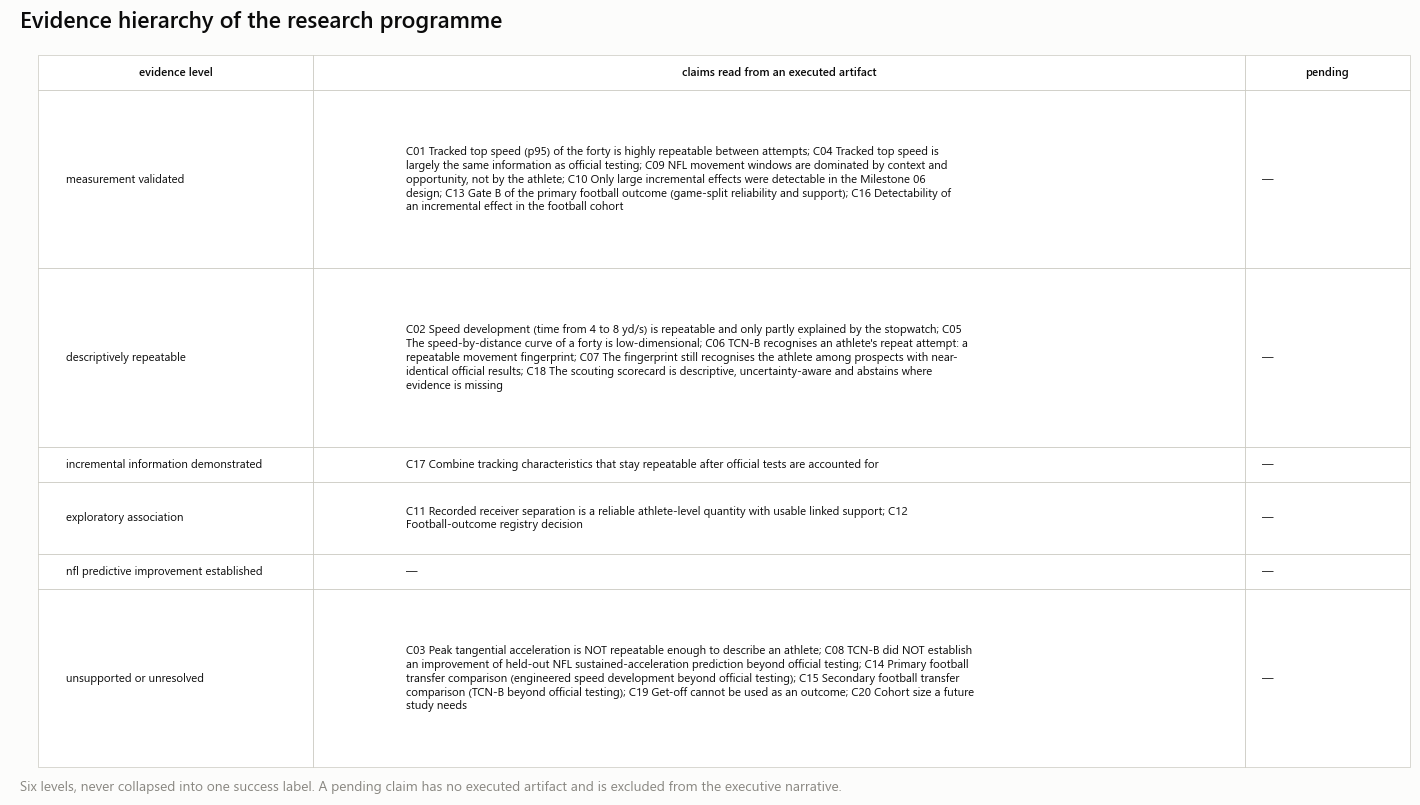

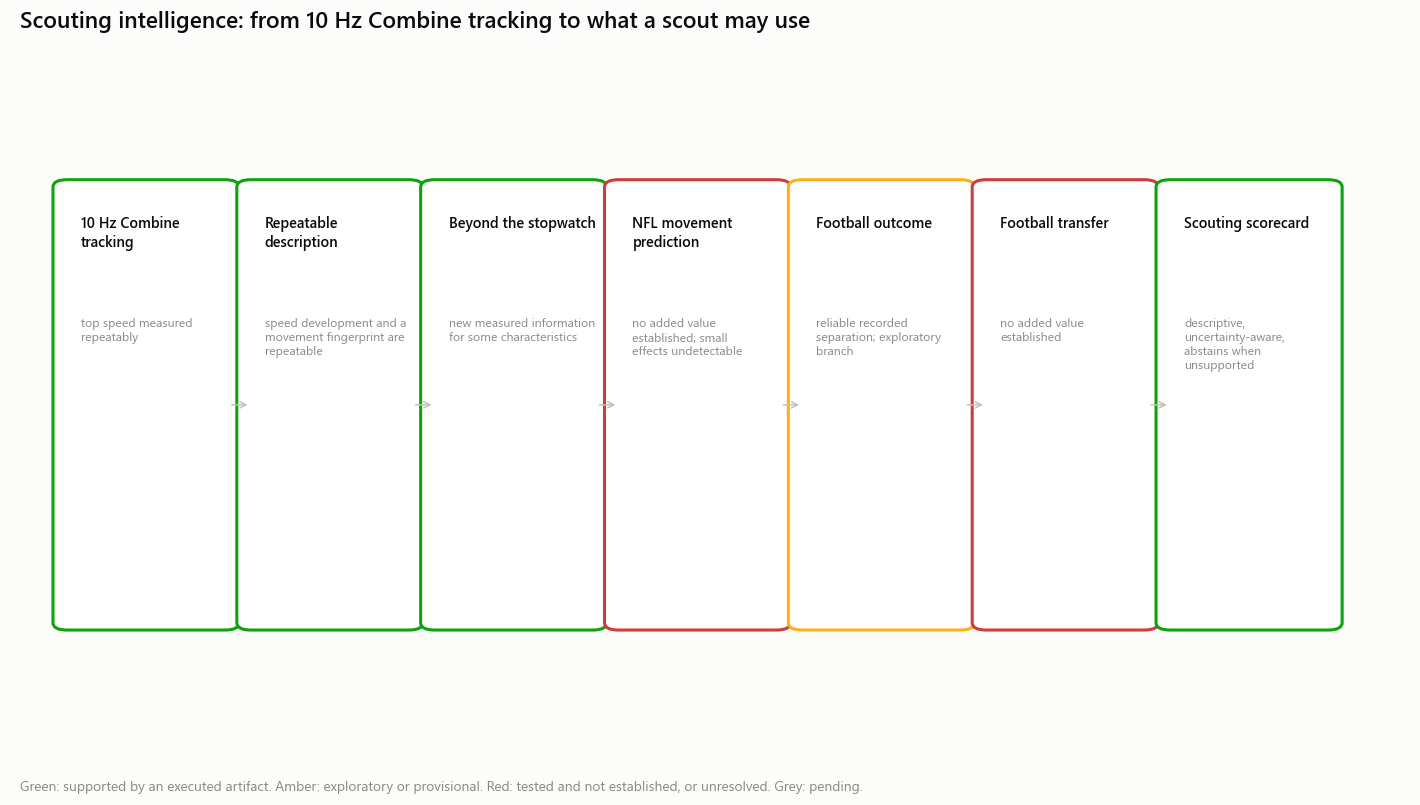

In [8]:
E = {r['claim_id']: r for r in evidence.iter_rows(named=True)}

def box(title, ids, when_done, key_done):
    rows = [E[i] for i in ids if i in E]
    if not rows or not all(r['executed'] for r in rows):
        return (title, 'pending: ' + ', '.join(r['claim_id'] for r in rows if not r['executed']), 'neutral')
    return (title, when_done, key_done)

c14 = E.get('C14', {})
transfer_key = {'nfl_predictive_improvement_established': 'good', 'exploratory_association': 'warning'}.get(c14.get('evidence_level'), 'critical')
transfer_txt = {'good': 'held-out improvement under a confirmed definition', 'warning': 'exploratory association only',
                'critical': 'no added value established'}[transfer_key]
c17 = E.get('C17', {})
BOXES = [box('10 Hz Combine tracking', ['C01'], 'top speed measured repeatably', 'good'),
         box('Repeatable description', ['C02', 'C06'], 'speed development and a movement fingerprint are repeatable', 'good'),
         box('Beyond the stopwatch', ['C04', 'C17'], 'new measured information for some characteristics' if c17.get('evidence_level') == 'incremental_information_demonstrated'
             else 'mostly redundant with official tests', 'good' if c17.get('evidence_level') == 'incremental_information_demonstrated' else 'warning'),
         box('NFL movement prediction', ['C08', 'C10'], 'no added value established; small effects undetectable', 'critical'),
         box('Football outcome', ['C11', 'C12', 'C13'], 'reliable recorded separation; ' + BRANCH['name'] + ' branch', 'warning' if BRANCH['name'] != 'frozen' else 'good'),
         box('Football transfer', ['C14'], transfer_txt, transfer_key),
         box('Scouting scorecard', ['C18'], 'descriptive, uncertainty-aware, abstains when unsupported', 'good')]
store.show(ff.fig_hierarchy(evidence, ep.LEVELS), 'AM08B6_01_evidence_hierarchy', {'evidence': evidence}, publication=True, source='final_evidence_registry',
           n=f'{int(evidence["executed"].sum())} of {evidence.height} claims executed')
store.show(ff.fig_intelligence_diagram(BOXES), 'AM08B6_02_scouting_intelligence_diagram', {'evidence': evidence}, publication=True, source='final_evidence_registry',
           n='claims C01–C20')

## 5 · Gate F — competition package

Does every claim trace to an executed artifact? A pending claim is **excluded from the executive narrative** and stays visible as pending. The gate passes only when no report still shows a pending token.

In [9]:
gate = save(ep.gate_f(evidence, PENDING_TOKENS, story), ep.GATE_F)
GATE_F = 'PASS' if bool(gate['passed'].all()) else 'INCOMPLETE'
with pl.Config(fmt_str_lengths=240, tbl_rows=-1):
    display(gate)
if controls.save_tables:
    store.write_json('final_package_manifest', {'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'gate_f': GATE_F, 'football_branch': BRANCH,
                                                'claims_executed': int(evidence['executed'].sum()), 'claims_total': evidence.height, 'pending_tokens': PENDING_TOKENS,
                                                'story_steps_available': int(story['available'].sum()), 'reports_written': WRITE_REPORTS, 'provenance': PROV})
print('Gate F:', GATE_F)

23:44:29 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B6] football_gate_f_package: 4 rows → warehouse/gold/advanced_movement/football_v1/football_gate_f_package.parquet


criterion,passed,detail
str,bool,str
"""narrative_uses_executed_claims_only""",true,"""20 of 20 claims read from an executed artifact"""
"""evidence_levels_kept_apart""",true,"""descriptively_repeatable 5, exploratory_association 2, incremental_information_demonstrated 1, measurement_validated 6, unsupported_or_unresolved 6"""
"""no_pending_token_in_reports""",true,"""none pending"""
"""visual_story_complete (informative)""",true,"""11 of 12 story steps have a saved figure"""


Gate F: PASS


## 6 · Reading

- `INCOMPLETE` is an honest state: it lists exactly which notebooks still have to run. Rerun this notebook after each of them — it is cheap and idempotent.
- The final answer of the project is the sentence the evidence supports, whichever it is: *predictive benefit quantified under held-out validation with its uncertainty* — or *a robust descriptive scouting system, the reliable additional information, and the reason the evidence does not support predictive talent rankings*.

**Send back:** the evidence table, the pending list, the story table, Gate F, figures `AM08B6_01`, `02`, and `reports/NFL_BDB_2027_EXECUTIVE_SUMMARY.md`.